In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

# Configuração visual dos gráficos
sb.set_theme(style="whitegrid")

# 1. Carregamento direto dos dados limpos e tratados
caminho_dados = r"../data/processed/dados_sensores_aeromotion_tratado.csv"
df_limpo = pd.read_csv(caminho_dados)
df_limpo['timestamp'] = pd.to_datetime(df_limpo['timestamp'])

print(f"Dataset carregado com sucesso: {df_limpo.shape[0]} linhas e {df_limpo.shape[1]} colunas.")
df_limpo.head()

Dataset carregado com sucesso: 12000 linhas e 20 colunas.


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha,temp_rolling_mean_1h,temp_rolling_std_1h,temp_rolling_mean_6h,temp_rolling_std_6h,vib_rolling_mean_1h,vib_rolling_std_1h,vib_rolling_mean_6h,vib_rolling_std_6h,severidade_dinamica
0,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,2.500,3.51,2382.7,44.97,18.73,0,57.830000,0.000000,57.830000,0.000000,2.500000,0.000000,2.500000,0.000000,0.001049
1,2026-01-01 01:00:00,TURB-101,Carga_Media,101.4,58.03,2.500,4.00,2925.2,52.83,27.75,0,57.930000,0.141421,57.930000,0.141421,2.500000,0.000000,2.500000,0.000000,0.000855
2,2026-01-01 01:10:00,TURB-101,Carga_Alta,101.5,75.77,7.985,4.68,3569.7,63.52,37.74,0,63.876667,10.300414,63.876667,10.300414,4.328333,3.166766,4.328333,3.166766,0.002237
3,2026-01-01 02:30:00,TURB-101,Carga_Media,106.4,64.11,13.470,4.19,3011.2,49.74,42.56,2,63.935000,8.411062,63.935000,8.411062,6.613750,5.251488,6.613750,5.251488,0.004473
4,2026-01-01 03:30:00,TURB-101,Cruzeiro,109.2,49.55,1.280,4.08,2477.4,44.98,18.99,0,61.058000,9.718288,61.058000,9.718288,5.547000,5.135501,5.547000,5.135501,0.000517


In [4]:
print("Valores ausentes (NaN) por coluna:")
print(df_limpo.isna().sum())

print("\nFaixas operacionais pós-tratamento:")
print(f"Temperatura Mancal (°C): Mín {df_limpo['temperatura_mancal_c'].min():.1f} | Máx {df_limpo['temperatura_mancal_c'].max():.1f}")
print(f"Vibração RMS (mm/s): Mín {df_limpo['vibracao_rms_mms'].min():.2f} | Máx {df_limpo['vibracao_rms_mms'].max():.2f}")

Valores ausentes (NaN) por coluna:
timestamp                    0
id_equipamento               0
modo_operacao                0
horas_operacao_acumuladas    0
temperatura_mancal_c         0
vibracao_rms_mms             0
pressao_oleo_bar             0
rotacao_rpm                  0
emissao_acustica_db          0
corrente_eletrica_amp        0
tipo_falha                   0
temp_rolling_mean_1h         0
temp_rolling_std_1h          0
temp_rolling_mean_6h         0
temp_rolling_std_6h          0
vib_rolling_mean_1h          0
vib_rolling_std_1h           0
vib_rolling_mean_6h          0
vib_rolling_std_6h           0
severidade_dinamica          0
dtype: int64

Faixas operacionais pós-tratamento:
Temperatura Mancal (°C): Mín 40.0 | Máx 119.6
Vibração RMS (mm/s): Mín 0.08 | Máx 15.17


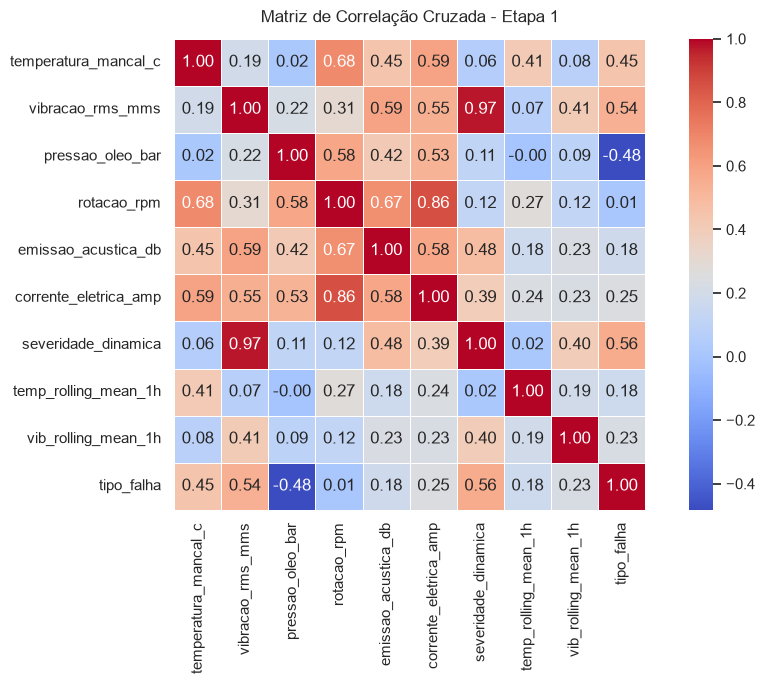

In [5]:
colunas_eda = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar',
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp',
    'severidade_dinamica', 'temp_rolling_mean_1h', 'vib_rolling_mean_1h', 'tipo_falha'
]

plt.figure(figsize=(10, 7))
sb.heatmap(df_limpo[colunas_eda].corr(), annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=0.5)
plt.title('Matriz de Correlação Cruzada - Etapa 1', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_16088\3182982081.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='modo_operacao', y='rotacao_rpm', ax=axes[0], palette='Set2')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_16088\3182982081.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='modo_operacao', y='temperatura_mancal_c', ax=axes[1], palette='Set2')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_16088\3182982081.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(d

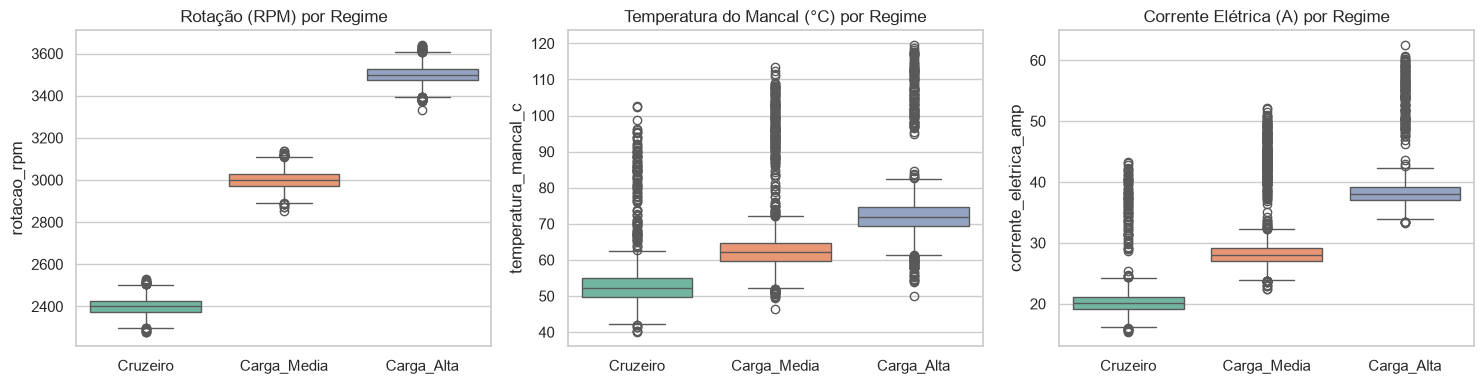

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sb.boxplot(data=df_limpo, x='modo_operacao', y='rotacao_rpm', ax=axes[0], palette='Set2')
axes[0].set_title('Rotação (RPM) por Regime')
axes[0].set_xlabel('')

sb.boxplot(data=df_limpo, x='modo_operacao', y='temperatura_mancal_c', ax=axes[1], palette='Set2')
axes[1].set_title('Temperatura do Mancal (°C) por Regime')
axes[1].set_xlabel('')

sb.boxplot(data=df_limpo, x='modo_operacao', y='corrente_eletrica_amp', ax=axes[2], palette='Set2')
axes[2].set_title('Corrente Elétrica (A) por Regime')
axes[2].set_xlabel('')

plt.tight_layout()
plt.show()

C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_16088\573903230.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='modo_operacao', y='rotacao_rpm', ax=axes[0], palette='Set2')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_16088\573903230.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='modo_operacao', y='temperatura_mancal_c', ax=axes[1], palette='Set2')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_16088\573903230.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=

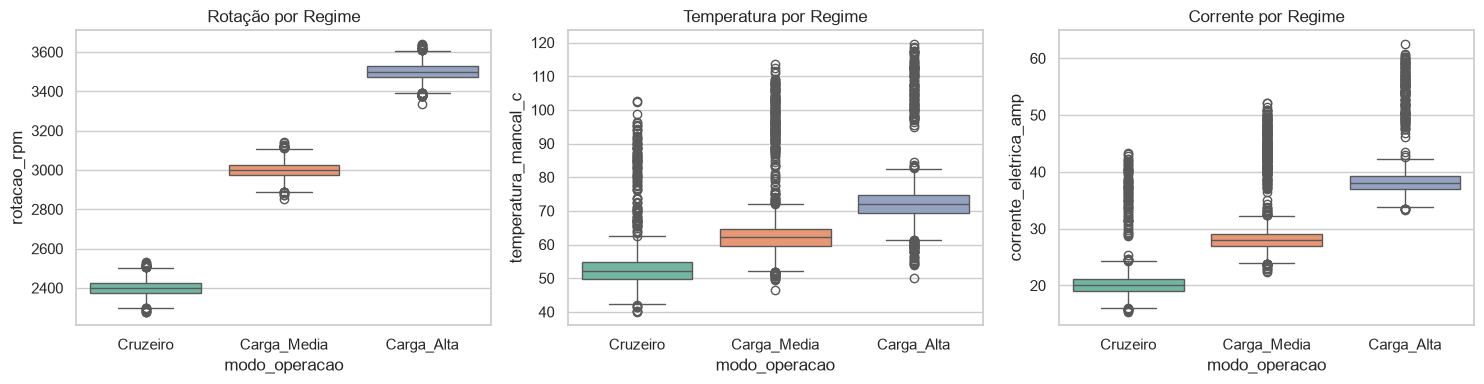

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sb.boxplot(data=df_limpo, x='modo_operacao', y='rotacao_rpm', ax=axes[0], palette='Set2')
axes[0].set_title('Rotação por Regime')

sb.boxplot(data=df_limpo, x='modo_operacao', y='temperatura_mancal_c', ax=axes[1], palette='Set2')
axes[1].set_title('Temperatura por Regime')

sb.boxplot(data=df_limpo, x='modo_operacao', y='corrente_eletrica_amp', ax=axes[2], palette='Set2')
axes[2].set_title('Corrente por Regime')

plt.tight_layout()
plt.show()